In [11]:
import numpy as np
import pandas as pd

df = pd.read_parquet('processed/df2_imputed.parquet')

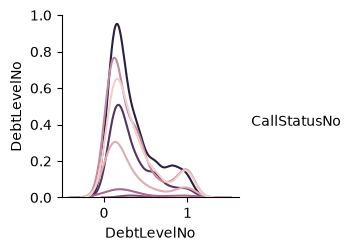

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.pairplot(
    df[['CallStatusNo', 'DebtLevelNo']],
    hue="CallStatusNo",
    diag_kind="kde",
    diag_kws={"fill": False},  # Outlined lines for diagonal distributions
)
plt.show()

# Mutual Info Regression

In [13]:
nonnum_cols = ['State', 'VendorLeadID', 'Date', 'CallStatusNo']

In [14]:
from sklearn.feature_selection import mutual_info_classif
# 2. Mutual Information
df.dropna(inplace=True)
X = df.drop(columns=["CallStatusNo"]+nonnum_cols)
y = df["CallStatusNo"]

mi_scores = mutual_info_classif(X, y)
mi_df = pd.DataFrame({"Feature": X.columns, "MI Score": mi_scores}).sort_values(
    by="MI Score", ascending=False
)
mi_df.head()

ValueError: could not convert string to float: 'AdKnowledge'

\section{Drivers of Lead Quality}

\begin{quote}
	What can we learn about the drivers of "lead quality" from this dataset? What segments -- where the ad was shown, what kind of person filled out the ad, what kind of ad did they see -- have differing lead quality rates?
\end{quote}


\subsection{Definition of Lead Quality}

The objective of this analysis is to identify characteristics of a lead, its acquisition channel, and the advertisement that generated it that are associated with downstream lead quality. We distinguish between two outcomes. A lead is classified as \emph{qualified} if its final call status corresponds to one of the stages \texttt{EP Sent}, \texttt{EP Confirmed}, \texttt{EP Received}, or \texttt{Closed}. We also examine \emph{closed} leads separately as a stricter measure of commercial success.

There are 3,021 observations in the cleaned dataset. Overall, 393 leads are classified as qualified, giving an overall qualification rate of approximately \(13.0\%\). Of these, 245 eventually reach the \emph{Closed} status, corresponding to an overall closure rate of approximately \(8.1\%\).

Throughout this section, comparisons of lead quality are primarily based on the qualification rate
\[
\widehat{p}_Q(g)
=
\frac{\#\{\text{qualified leads in segment }g\}}
{\#\{\text{leads in segment }g\}},
\]
with the corresponding closure rate reported where it provides additional insight. Differences between categorical variables and lead quality are assessed using Pearson's chi-squared test. These tests establish evidence of association, not causation.



\subsection{Ad Type and Search Intent}

The strongest evidence of systematic differences in lead quality is associated with the type of problem represented by the advertisement or search intent. The cleaned variable \texttt{AdGroupFamily} groups the many individual ad groups into broader categories such as Debt Settlement, Debt Consolidation, Bankruptcy, Student Debt, and Loan Default.

The association between \texttt{AdGroupFamily} and qualification is highly statistically significant,
\[
p \approx 1.0\times 10^{-11}.
\]
The magnitude of the differences is also substantial.

\begin{table}[h]
	\centering
	\caption{Qualification and closure rates by ad-group family.}
	\label{tab:adgroup-quality}
	\begin{tabular}{lrrr}
		\toprule
		\textbf{Ad-group family} & \textbf{Leads} & \textbf{Qualified} & \textbf{Closed} \\
		\midrule
		Debt Settlement       & 62  & 19.4\% & 16.1\% \\
		Stop Collections      & 58  & 19.0\% & 13.8\% \\
		Consolidate           & 169 & 18.9\% & 12.4\% \\
		Holding Tank          & 339 & 18.0\% & 14.5\% \\
		General Debt          & 435 & 17.2\% & 10.1\% \\
		Debt Consolidation    & 349 & 16.9\% & 7.2\% \\
		Free / Generic        & 125 & 12.8\% & 7.2\% \\
		Debt Reduction        & 102 & 11.8\% & 6.9\% \\
		Bankruptcy             & 274 & 11.3\% & 7.7\% \\
		Credit Card Debt      & 351 & 10.3\% & 5.7\% \\
		Lower Payments        & 202 & 6.9\%  & 5.0\% \\
		Student Debt          & 392 & 2.3\%  & 1.0\% \\
		Loan Default          & 72  & 1.4\%  & 1.4\% \\
		\bottomrule
	\end{tabular}
\end{table}

The differences are economically large. Leads associated with Debt Settlement have a qualification rate of \(19.4\%\), approximately one and a half times the overall rate of \(13.0\%\). By contrast, Student Debt leads qualify at only \(2.3\%\), while Loan Default leads qualify at approximately \(1.4\%\).

The difference is even more pronounced when considering final closure. Debt Settlement has a closure rate of \(16.1\%\), whereas Student Debt has a closure rate of only \(1.0\%\). Thus, the observed pattern is not confined to an intermediate qualification stage; it also appears in the final commercial outcome.

This suggests that \emph{the intent represented by the advertisement is one of the most important observable dimensions of lead quality}. In particular, leads associated with settlement, negotiation, collections, and consolidation appear substantially more valuable than leads associated with student debt, loan default, or simply lowering payments.

It is important, however, not to interpret these results as evidence that changing an advertisement to a particular topic would mechanically produce the corresponding qualification rate. Ad-group family is correlated with acquisition source, campaign, applicant characteristics, and other aspects of the advertising process. The result should therefore initially be interpreted as a segmentation finding.



\subsection{Applicant Debt Level}

The financial characteristics of the person submitting the lead also show a strong relationship with lead quality. The association between debt level and qualification is statistically significant,
\[
p \approx 1.5\times10^{-5}.
\]

The relationship is distinctly non-monotone. The highest qualification rates occur in the \$70,000--\$90,000 and \$10,000--\$15,000 ranges, at approximately \(19.1\%\) and \(18.6\%\), respectively. In contrast, the \$7,500--\$10,000 group has a qualification rate of only \(7.0\%\), while leads reporting more than \$100,000 of debt qualify at approximately \(6.8\%\).

\begin{table}[h]
	\centering
	\caption{Qualification rates by applicant debt level.}
	\label{tab:debt-quality}
	\begin{tabular}{lrr}
		\toprule
		\textbf{Debt level} & \textbf{Qualified} & \textbf{Closed} \\
		\midrule
		\$70k--90k   & 19.1\% & 13.7\% \\
		\$10k--15k   & 18.6\% & 11.7\% \\
		\$20k--30k   & 15.8\% & 9.8\% \\
		\$50k--70k   & 15.5\% & 9.7\% \\
		\$15k--20k   & 14.0\% & 8.7\% \\
		\$30k--50k   & 12.3\% & 7.6\% \\
		\$90k--100k  & 12.2\% & 7.8\% \\
		\$7.5k--15k  & 11.4\% & 7.1\% \\
		\$7.5k--10k  & 7.0\%  & 5.0\% \\
		\$100k+      & 6.8\%  & 3.7\% \\
		\bottomrule
	\end{tabular}
\end{table}

Consequently, there is no basis for the simple claim that ``more debt produces better leads.'' Instead, the data suggest a more complicated relationship between the size of the applicant's debt and lead quality. One possible interpretation is that there is a range of debt severity in which the customer's financial problem is sufficiently substantial to motivate action while remaining commercially addressable. This interpretation is only a hypothesis and would require a multivariate analysis to establish.



\subsection{Acquisition Partner}

The acquisition partner is another strong discriminator of lead quality. The association between \texttt{Partner} and qualification is statistically significant,
\[
p \approx 1.3\times10^{-5}.
\]

\begin{table}[h]
	\centering
	\caption{Lead quality by acquisition partner.}
	\label{tab:partner-quality}
	\begin{tabular}{lrrr}
		\toprule
		\textbf{Partner} & \textbf{Leads} & \textbf{Qualified} & \textbf{Closed} \\
		\midrule
		AdKnowledge  & 171 & 18.7\% & 12.3\% \\
		Call\_Center & 271 & 16.2\% & 9.6\% \\
		yahoo        & 958 & 14.2\% & 7.7\% \\
		google       & 979 & 13.8\% & 9.9\% \\
		Google       & 639 & 7.0\%  & 4.1\% \\
		\bottomrule
	\end{tabular}
\end{table}

AdKnowledge produces the highest observed qualification rate at \(18.7\%\), whereas the capitalized \texttt{Google} category produces only \(7.0\%\). The distinction between \texttt{google} and \texttt{Google} should not be interpreted literally as a capitalization effect. Rather, it is almost certainly evidence of two different acquisition or tracking streams that have been recorded under different labels.

The practical conclusion is therefore that \emph{the acquisition source or partner is strongly associated with downstream lead quality}.



\subsection{Marketing Campaign}

The consolidated marketing campaign variable also shows statistically significant differences,
\[
p \approx 0.0023.
\]

\begin{table}[h]
	\centering
	\caption{Lead quality by marketing campaign.}
	\label{tab:campaign-quality}
	\begin{tabular}{lrrr}
		\toprule
		\textbf{Campaign} & \textbf{Leads} & \textbf{Qualified} & \textbf{Closed} \\
		\midrule
		FS  & 171  & 18.7\% & 12.3\% \\
		DHT & 339  & 18.0\% & 14.5\% \\
		DV  & 168  & 16.1\% & 8.9\% \\
		C   & 101  & 13.9\% & 11.9\% \\
		S   & 100  & 13.0\% & 11.0\% \\
		DRI & 1496 & 11.2\% & 5.9\% \\
		DC  & 36   & 11.1\% & 2.8\% \\
		DG  & 334  & 8.7\%  & 6.0\% \\
		\bottomrule
	\end{tabular}
\end{table}

The DHT and FS campaigns perform particularly well, while DRI generates a large volume of leads but a substantially lower qualification and closure rate. This illustrates the distinction between \emph{lead volume} and \emph{lead quality}: the campaign producing the greatest number of leads need not be the campaign producing the greatest number of commercially valuable leads per acquisition.



\subsection{Advertising Creative}

The cleaned \texttt{Fieldset} variable captures the main creative/widget categories. The observed rates differ across creatives, but the evidence is weaker than for ad-group family, partner, debt level, and campaign. The overall association has
\[
p\approx0.10.
\]

Some creatives nevertheless deserve attention. For example, the ``yellowarrow'' creative has an observed qualification rate of approximately \(24.5\%\), whereas ``Head3'' has approximately \(6.7\%\). However, the yellowarrow category contains only 49 observations, so its high rate is estimated with considerable uncertainty.

Consequently, the appropriate conclusion is that \emph{creative may affect lead quality, but this dataset does not provide sufficiently strong statistical evidence to rank individual creatives confidently}. The more robust signal appears to come from the underlying topic or intent of the advertisement rather than its graphical presentation alone.



\subsection{Physical Ad Placement}

The data provide comparatively little evidence that the physical placement of the advertisement is an important determinant of lead quality.

The two main placement categories have the following observed rates:

\begin{table}[h]
	\centering
	\caption{Lead quality by physical ad placement.}
	\label{tab:placement-quality}
	\begin{tabular}{lrrr}
		\toprule
		\textbf{Placement} & \textbf{Leads} & \textbf{Qualified} & \textbf{Closed} \\
		\midrule
		Top Right -- 300$\times$250 & 271  & 16.2\% & 9.6\% \\
		Top Left -- 302$\times$252  & 2750 & 12.7\% & 8.0\% \\
		\bottomrule
	\end{tabular}
\end{table}

Although the raw difference is approximately 3.5 percentage points, the corresponding test gives
\[
p\approx0.12.
\]
Thus, the data do not provide strong evidence that changing the physical placement alone would materially change lead quality.

This is also consistent with the structure of the advertising data: different placements contain different mixtures of campaigns and creatives. An apparent placement effect may therefore be a consequence of differences in the composition of advertisements shown in each location.



\subsection{Other Applicant Characteristics}

Phone quality provides a smaller but statistically significant signal. The association between \texttt{PhoneScore} and qualification has
\[
p\approx0.020.
\]
The qualification rate is \(16.2\%\) for score 5, \(11.7\%\) for score 3, \(9.9\%\) for score 2, and \(7.1\%\) for score 4. Since the relationship is not monotone, PhoneScore should be treated as a categorical variable rather than assuming that quality increases linearly with the score.

By contrast, \texttt{AddressScore} provides little evidence of a systematic difference in qualification rates:
\[
p\approx0.31.
\]

State also does not provide convincing evidence of a systematic effect:
\[
p\approx0.51.
\]
Some individual states have high or low observed qualification rates, but the overall state effect is not statistically significant. In addition, many states contain relatively small numbers of observations, making extreme observed rates unsurprising. The data therefore do not justify geographic targeting decisions based on state alone.

Email-provider categories show a weaker association with qualification, with some providers having noticeably different observed rates. This variable should nevertheless be interpreted cautiously: email provider is likely acting as a proxy for demographic or acquisition characteristics rather than being a causal determinant of lead quality.



\subsection{Overall Interpretation}

The evidence points toward three principal dimensions of lead quality:

\begin{enumerate}
	\item \textbf{Intent:} The type of financial problem that motivated the lead is the strongest observable discriminator. Settlement, collections, and consolidation-related intent produce substantially better leads than student-debt and loan-default intent.
	
	\item \textbf{Applicant financial profile:} Debt level is strongly associated with quality, although the relationship is non-monotonic. The best-performing debt bands are not simply the bands with the largest debts.
	
	\item \textbf{Acquisition source:} Partner and campaign are strongly associated with downstream quality, suggesting that the origin and targeting of traffic matter substantially.
\end{enumerate}

In contrast, there is considerably weaker evidence that \emph{where} the advertisement was physically displayed matters independently. The data therefore suggest that lead quality is primarily an \emph{intent-and-fit} problem rather than a simple placement problem.

The difference between the strongest and weakest intent segments illustrates the magnitude of the effect. Debt Settlement leads have a qualification rate of approximately \(19.4\%\) and a closure rate of \(16.1\%\), whereas Student Debt leads have qualification and closure rates of only \(2.3\%\) and \(1.0\%\), respectively. Thus, the latter segment generates leads at roughly one-eighth of the qualification rate and one-sixteenth of the closure rate of the former.



\subsection{Implications for Marketing Strategy}

The results suggest that optimizing advertising solely for the number of leads generated would be misleading. A campaign can generate a large number of inexpensive leads while producing relatively few commercially valuable customers.

A more appropriate optimization target is therefore something closer to
\[
\text{Expected value per lead}
=
P(\text{qualified}\mid X)
\times
P(\text{closed}\mid\text{qualified},X)
\times
\text{value of a closed lead},
\]
rather than simply maximizing
\[
\text{number of leads}.
\]

In practical terms, the data suggest prioritizing acquisition channels and ad themes associated with settlement, negotiation, collections, and consolidation intent, while treating student-debt and loan-default traffic with considerably more caution. Campaigns should ideally be evaluated on downstream qualification and closure rather than raw form submissions.



\subsection{Limitations and Next Steps}

The analysis is observational. The reported differences are associations and should not be interpreted as causal effects. In particular, ad-group family, marketing campaign, partner, landing page, creative, and applicant characteristics are not independently randomized and may be strongly correlated.

The next step should therefore be a multivariate analysis of the form
\[
P(Q=1\mid X)
=
\operatorname{logit}^{-1}
\left(
\beta_0+\beta^\top X
\right),
\]
where \(X\) includes applicant characteristics, acquisition source, campaign, ad-group family, search intent, landing page, and relevant ad characteristics.

A shallow decision tree or ensemble model can then be used alongside logistic regression to identify nonlinearities and interactions. The purpose of this second stage should not merely be prediction, but to determine whether the strongest univariate findings---particularly ad intent, debt level, and acquisition source---remain important after accounting for one another.

Overall, the descriptive analysis provides a clear initial conclusion: \textbf{the quality of a lead is much more strongly associated with what problem the person appears to be trying to solve, their financial profile, and where the traffic originated than with the physical position in which the advertisement was displayed.}


# Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Train/Test Split & Scaling
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Multinomial Logistic Regression (Drop multi_class)
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_scaled, y_train)
print("Logistic Regression Score:", log_reg.score(X_test_scaled, y_test))

Logistic Regression Score: 0.43661971830985913


# Random Forest

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.impute import SimpleImputer

# Filter rows where target CallStatusNo is not null
df_model = df[df['CallStatusNo'].notnull()].copy()

# Ensure target is integer type
df_model['CallStatusNo'] = df_model['CallStatusNo'].astype(int)

print("Target value counts:")
print(df_model['CallStatusNo'].value_counts().sort_index())

# Identify numerical features
# Exclude non-feature columns like Unnamed: 0, Email, VendorLeadID, Date, and target CallStatusNo
exclude_cols = ['Unnamed: 0', 'Email', 'VendorLeadID', 'Date', 'CallStatusNo']
num_cols = [c for c in df_model.select_dtypes(include=[np.number]).columns if c not in exclude_cols]

print(f"\nNumber of numerical features: {len(num_cols)}")

X = df_model[num_cols]
y = df_model['CallStatusNo']

# Impute missing values in features with median
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

# Train-Test Split (80/20) with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y, test_size=0.2, random_state=42, stratify=y
)

# Train Random Forest Classifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Evaluate
y_pred = rf.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"\nAccuracy: {acc:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Feature Importance
importances = rf.feature_importances_
feature_imp = pd.Series(importances, index=num_cols).sort_values(ascending=False)

print("\nTop 15 Most Important Features:")
print(feature_imp.head(15))

Target value counts:
CallStatusNo
1     56
2     26
3    120
4      7
6     66
7     79
Name: count, dtype: int64

Number of numerical features: 43

Accuracy: 0.2958

Classification Report:
              precision    recall  f1-score   support

           1       0.40      0.18      0.25        11
           2       0.00      0.00      0.00         5
           3       0.34      0.58      0.43        24
           4       0.00      0.00      0.00         2
           6       0.10      0.08      0.09        13
           7       0.33      0.25      0.29        16

    accuracy                           0.30        71
   macro avg       0.20      0.18      0.18        71
weighted avg       0.27      0.30      0.26        71


Top 15 Most Important Features:
StateNo                                0.267547
DebtLevelNo                            0.196982
PhoneScore                             0.111312
AddressScore                           0.088386
Fieldset_white                         0.0

Text(847.1969696969695, 0.5, 'Actual CallStatusNo')

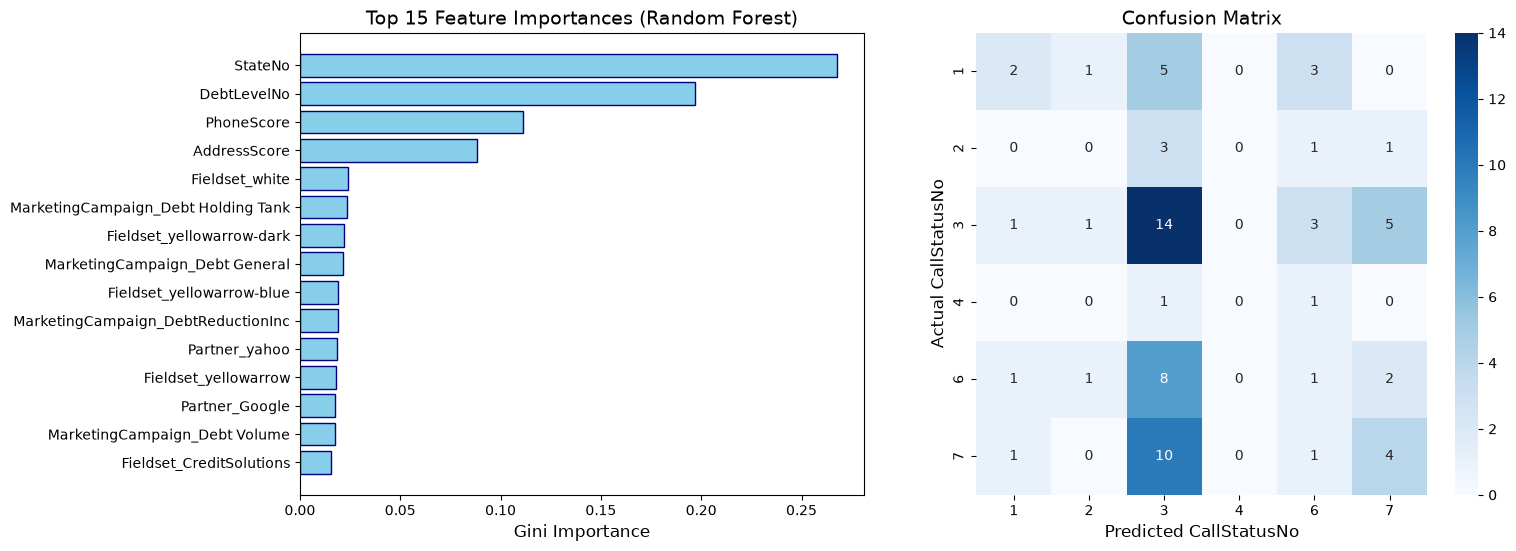

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot Top 15 Feature Importances
top_features = feature_imp.head(15).sort_values(ascending=True)
axes[0].barh(top_features.index, top_features.values, color='skyblue', edgecolor='navy')
axes[0].set_title('Top 15 Feature Importances (Random Forest)', fontsize=14)
axes[0].set_xlabel('Gini Importance', fontsize=12)

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=rf.classes_, yticklabels=rf.classes_)
axes[1].set_title('Confusion Matrix', fontsize=14)
axes[1].set_xlabel('Predicted CallStatusNo', fontsize=12)
axes[1].set_ylabel('Actual CallStatusNo', fontsize=12)
